# 21 — exp0e: the stopping rule under correlated Monte Carlo noise

Notebook 20 again, with one change: the Monte Carlo draws are common random numbers, as in the simulator. Each seed draws one set of 10^5 uniform numbers, shared by every sample; a sample with probability P counts those below P as losses. Neighbouring samples then have nearly the same error, so the noisy surface stays smooth, as the CNS campaigns' did. Question: does "max straddle < 0" now fire, and is the classification right when it does? Cached in `results/exp0e_stop_rule_crn.pkl`.

In [1]:
import hashlib
import os
import pickle
import sys
import time
from pathlib import Path

os.environ["VECLIB_MAXIMUM_THREADS"] = "1"          # one BLAS thread per worker: the workers are the parallelism
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"                # Linux numpy
os.environ["MKL_NUM_THREADS"] = "1"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from joblib import Parallel, delayed
from scipy import special, stats
from mvlse import run_lse, score_level_set
from mvlse.benchmark import test_grid
from mvlse.problems import get_problem

sys.path.insert(0, str(Path.cwd().parent))
import common
import config

P = config.EXPERIMENTS["exp0_verify"]                # same test-cases, seeds, 250 samples, 1 initial per category
TAU = config.TAU                                     # log10 1e-3
N_MC = config.N_ENCOUNTERS                           # 1e5 encounters per sample, as the campaigns
B = 4.6                                              # slope of the probability surface (see the next cell)
CONDITIONS = {"A: exact, straddle": {"se": False, "acquisition": "straddle"}}   # as the campaigns run
N_WORKERS = int(os.environ.get("TRC_N_WORKERS", "6"))
CACHE = Path("results/exp0e_stop_rule_crn.pkl")
print(P)
print(common.code_state(), f"workers: {N_WORKERS}")

{'problems': ['goldstein36_graded', 'goldstein36_flip', 'himmelblau36_graded'], 'methods': ['category_wise', 'dc', 'gower', 'hs_dim'], 'seeds': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10], 'max_evaluations': 250, 'n_init_per_category': 1}
{'mvlse': {'commit': 'f5dbe1fa869cc9627a3e231c4d0271d63875c0f5', 'dirty': False}, 'blueskycdarr': {'commit': '030c0f459a3c5491cef88485e2672aef60a14179', 'dirty': False}} workers: 30


In [2]:
# Each analytical test-case becomes a probability surface, sampled by Monte Carlo.
#   z = Phi^-1(F(f))   normal score of the test function over its domain (F: its distribution on the test grid)
#   P = logistic(logit(1e-3) + B (z - z_tau))
# Monotone in f, so P <= 1e-3 exactly where f <= its threshold: the level set is notebook 10's. All
# test-cases share one distribution of P over the domain; B = 4.6 puts 15% of the Goldstein domain on
# the zero-loss floor and the rest up to P ~ 1. A sample draws Binomial(1e5, P) losses and reports the
# simulator's own estimate: log10 of the Jeffreys proportion, with its delta-method standard error.
# The draw is a fixed function of (point, seed), like the simulator at seed 7.
# (scipy functions are called through their module: a ufunc imported into the notebook's namespace
# is pickled as __main__.<name>, which the worker processes do not have.)
def surface(name):
    prob = get_problem(name)
    grid = test_grid(prob)
    f_grid = prob.truth(grid)
    s = np.sort(f_grid); n = len(s)
    u_axis = (np.arange(1, n + 1) - 0.5) / n
    F = lambda v: np.interp(v, s, u_axis, left=0.5 / n, right=1 - 0.5 / n)
    z_tau = stats.norm.ppf(F(prob.threshold))
    log_p = lambda w: np.log10(special.expit(special.logit(10.0 ** TAU) + B * (stats.norm.ppf(F(prob.truth(w))) - z_tau)))
    return prob, grid, f_grid <= prob.threshold, log_p


def mc_blackbox(prob, log_p, seed, with_se):
    # Common random numbers, as the simulator: one set of N_MC uniform draws per seed, shared by every
    # point. A point with probability P counts the draws below P as losses, so nearby points see nearly
    # the same encounters and their Monte Carlo errors are correlated (identical P -> identical count).
    u = np.sort(np.random.default_rng(10_000 + seed).random(N_MC))
    def blackbox(points):
        w = prob.space.encode(points)
        out = []
        for lp in log_p(w):
            k = int(np.searchsorted(u, 10.0 ** lp))
            p_hat = (k + 0.5) / (N_MC + 1.0)
            se = np.sqrt(p_hat * (1 - p_hat) / N_MC) / (p_hat * np.log(10.0))
            out.append((float(np.log10(p_hat)), float(se)) if with_se else float(np.log10(p_hat)))
        return out
    return blackbox


def one_run(name, cond, seed):
    prob, grid, truth_inside, log_p = surface(name)
    t0 = time.perf_counter()
    res = run_lse(prob.space, mc_blackbox(prob, log_p, seed, CONDITIONS[cond]["se"]), threshold=TAU,
                  method=config.LSE["method"], correlation=config.LSE["correlation"], seed=seed,
                  acquisition=CONDITIONS[cond]["acquisition"], max_evaluations=P["max_evaluations"],
                  n_init_per_category=P["n_init_per_category"], flip_tolerance=config.LSE["flip_tolerance"],
                  stop_when_confident=False, monitor=grid, keep_snapshots=True, verbose=False)
    truth_lp = log_p(grid)
    f1 = [score_level_set(mu, truth_lp, TAU).f1 for mu, _ in res.snapshots]
    mu, sd = res.snapshots[-1]
    safe, unsafe = mu + 1.96 * sd <= TAU, mu - 1.96 * sd > TAU
    wrong = (mu <= TAU) != truth_inside
    rec = {
        "n": [r.n_evaluations for r in res.rounds], "f1": f1, "seconds": time.perf_counter() - t0,
        "safe": float(safe.mean()), "unsafe": float(unsafe.mean()), "ambiguous": float((~safe & ~unsafe).mean()),
        "false_safe": float((safe & ~truth_inside).mean()),          # confidently safe, truly unsafe
        "false_unsafe": float((unsafe & truth_inside).mean()),
        "errors_flagged": float(((~safe & ~unsafe) & wrong).sum() / max(wrong.sum(), 1)),
        "w": res.w, "y": res.y, "se": res.se, "level_correlations": res.level_correlations(),
        "max_straddle": [r.max_straddle for r in res.rounds],
    }
    # the round where max straddle < 0 first holds: the classification the stopping rule would return
    stop = next((i for i, r in enumerate(res.rounds) if r.max_straddle < 0), None)
    if stop is not None:
        mu_s, sd_s = res.snapshots[stop]
        safe_s = mu_s + 1.96 * sd_s <= TAU
        rec |= {"stop_n": res.rounds[stop].n_evaluations, "stop_f1": f1[stop],
                "stop_false_safe": float((safe_s & ~truth_inside).mean()),
                "stop_wrong": float(((mu_s <= TAU) != truth_inside).mean())}
    if res.labels is not None:                                       # Gotovos' own classification, on its candidates
        cand_inside = log_p(res.candidates) <= TAU
        lab = res.labels
        rec |= {"g_unclassified": float(np.mean(lab == 0)),
                "g_false_safe": float(np.mean((lab == 1) & ~cand_inside)),
                "g_false_unsafe": float(np.mean((lab == 2) & cand_inside)),
                "g_wrong_among_classified": float(np.sum(((lab == 1) & ~cand_inside) | ((lab == 2) & cand_inside))
                                                  / max(np.sum(lab > 0), 1))}
    return (name, cond, seed), rec


def run_all(jobs, cache):
    done = pickle.loads(cache.read_bytes()) if cache.exists() else {}
    todo = sorted((j for j in jobs if j not in done), key=lambda j: "himmelblau" not in j[0])
    print(f"{len(jobs) - len(todo)} of {len(jobs)} runs cached, {len(todo)} to run", flush=True)
    t0 = time.perf_counter()
    for key, rec in Parallel(n_jobs=N_WORKERS, return_as="generator_unordered")(delayed(one_run)(*j) for j in todo):
        done[key] = rec
        cache.write_bytes(pickle.dumps(done))
        print(f"[{(time.perf_counter() - t0) / 60:6.1f} min] {key[0]:20s} {key[1]:20s} seed {key[2]:2d}: "
              f"F1={rec['f1'][-1]:.4f} false-safe={rec['false_safe']:.4f} [{rec['seconds'] / 60:.1f} min]", flush=True)
    return done


runs = run_all([(n, c, s) for n in P["problems"] for c in CONDITIONS for s in P["seeds"]], CACHE)

0 of 30 runs cached, 30 to run


[  40.9 min] himmelblau36_graded  A: exact, straddle   seed  4: F1=0.7638 false-safe=0.0003 [40.8 min]


[  42.0 min] himmelblau36_graded  A: exact, straddle   seed  8: F1=0.7348 false-safe=0.0021 [42.0 min]


[  43.0 min] himmelblau36_graded  A: exact, straddle   seed  7: F1=0.7032 false-safe=0.0018 [43.0 min]


[  44.9 min] himmelblau36_graded  A: exact, straddle   seed  1: F1=0.6786 false-safe=0.0008 [44.9 min]


[  49.2 min] himmelblau36_graded  A: exact, straddle   seed  9: F1=0.7970 false-safe=0.0000 [49.2 min]


... (21 outputs left out)

[  85.1 min] goldstein36_graded   A: exact, straddle   seed  3: F1=0.9953 false-safe=0.0000 [85.0 min]


[  85.2 min] goldstein36_graded   A: exact, straddle   seed  4: F1=0.9931 false-safe=0.0002 [85.2 min]


[  85.3 min] goldstein36_graded   A: exact, straddle   seed  1: F1=0.9944 false-safe=0.0020 [85.3 min]


[ 106.6 min] goldstein36_flip     A: exact, straddle   seed  2: F1=0.9959 false-safe=0.0002 [106.5 min]


,rule fires,at sample,"F1 when it fires (mean, min)",misclassified when it fires,confidently safe but truly unsafe,F1 >= 0.99 first at,F1 at 250
problem,,,,,,,
goldstein36_graded,3/10,234,"0.9912, 0.9875",0.97%,0.494%,110,0.9936
goldstein36_flip,6/10,206,"0.9932, 0.9877",0.75%,0.326%,87,0.9942
himmelblau36_graded,1/10,36,"0.0000, 0.0000",5.54%,0.000%,never,0.7192


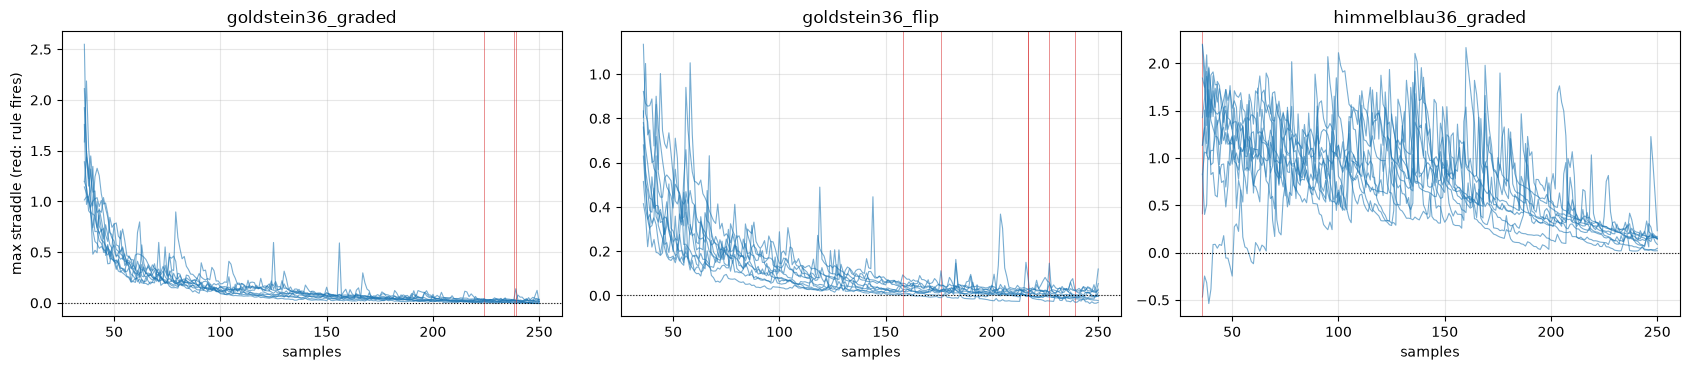

In [3]:
# The stopping rule under Monte Carlo noise: where would "max straddle < 0" have stopped each run, and how
# good was the classification there? (Notebook 10: deterministic responses; notebook 20: independent Monte Carlo noise.)
rows = []
for name in P["problems"]:
    rs = [runs[name, "A: exact, straddle", s] for s in P["seeds"]]
    stopped = [r for r in rs if "stop_n" in r]
    hit = [next((n for n, f in zip(r["n"], r["f1"]) if f >= 0.99), np.nan) for r in rs]
    rows.append({"problem": name, "rule fires": f"{len(stopped)}/{len(rs)}",
                 "at sample": f"{np.mean([r['stop_n'] for r in stopped]):.0f}" if stopped else "-",
                 "F1 when it fires (mean, min)": f"{np.mean([r['stop_f1'] for r in stopped]):.4f}, "
                                                 f"{np.min([r['stop_f1'] for r in stopped]):.4f}" if stopped else "-",
                 "misclassified when it fires": f"{100 * np.mean([r['stop_wrong'] for r in stopped]):.2f}%" if stopped else "-",
                 "confidently safe but truly unsafe": f"{100 * np.mean([r['stop_false_safe'] for r in stopped]):.3f}%" if stopped else "-",
                 "F1 >= 0.99 first at": f"{np.nanmean(hit):.0f}" if not np.all(np.isnan(hit)) else "never",
                 "F1 at 250": f"{np.mean([r['f1'][-1] for r in rs]):.4f}"})
table = pd.DataFrame(rows).set_index("problem")
table.to_csv("results/exp0e_stop_rule_crn.csv")
display(table)

fig, axes = plt.subplots(1, len(P["problems"]), figsize=(17, 3.8), squeeze=False)
for ax, name in zip(axes.flat, P["problems"]):
    for s in P["seeds"]:
        r = runs[name, "A: exact, straddle", s]
        ax.plot(r["n"], r["max_straddle"], color="C0", lw=0.8, alpha=0.6)
        if "stop_n" in r:
            ax.axvline(r["stop_n"], color="C3", lw=0.6, alpha=0.6)
    ax.axhline(0, color="k", lw=0.8, ls=":")
    ax.set_title(name); ax.set_xlabel("samples"); ax.grid(alpha=0.3)
axes.flat[0].set_ylabel("max straddle (red: rule fires)")
plt.tight_layout(); plt.savefig("results/exp0e_max_straddle_crn.png", dpi=130); plt.show()

## Insight

**1. With correlated noise the rule fires, but on an overconfident surrogate.**
- **How often:** on Goldstein it fired in 9 of 20 runs (3/10 graded, 6/10 flip), at 158–239 samples. With independent noise (notebook 20) it fired in none, and with exact responses (notebook 10) in all 20.
- **F1 when it fired:** 0.988–0.996.
- **Points confidently classified safe but truly unsafe:** up to 1.08% of the domain, 0.4% on average across those runs.

With exact responses, a stop came with F1 ≥ 0.998.

**2. Why.** Common random numbers keep the noisy surface smooth, so the surrogate interpolates it and becomes confident. Its confidence then covers the encounter set it was given, not the true $P(\mathrm{LoS})$. The shared Monte Carlo error is invisible to it. This is what notebook 19 found on the simulator: boundaries in the right place, but intervals far too narrow.

**3. The false stop right after the initial samples remains** (Himmelblau, sample 36, F1 = 0), as in notebook 20.

**For the paper:** "max straddle < 0" is not evidence of convergence when responses come from common random numbers. An independent check at higher $N$ (notebooks 16 and 19) is, and the interval should include the Monte Carlo error.